Task 4: NLP Sentiment Classification on Customer Reviews
Objective
Build a sentiment analysis model using TF-IDF text representations and machine learning classifiers to predict whether customer reviews are positive or negative.

Tools and Libraries
Python
Pandas
NumPy
NLTK
Scikit-Learn
Models
Multinomial Naive Bayes
Logistic Regression

Dataset Availability Note
The dataset link provided in the internship portal for Task 4 (NLP Sentiment Classification on Customer Reviews) returned a 404 "Not Found" error during project development.

As a result, the original dataset could not be downloaded. An alternative sentiment dataset / custom sample dataset was used to demonstrate the required NLP workflow, including text preprocessing, TF-IDF vectorization, sentiment classification, model evaluation, and custom sentiment prediction.

In [2]:
import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(
    "amazon_cells_labelled.txt",
    sep="\t",
    header=None,
    names=["review","sentiment"]
)

df.head()

,review,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     1000 non-null   str  
 1   sentiment  1000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 15.8 KB


In [5]:
df["sentiment"].value_counts()

sentiment
0    500
1    500
Name: count, dtype: int64

In [6]:
def clean_text(text):

    text = text.lower()

    text = re.sub(
        r"[^a-zA-Z\s]",
        "",
        text
    )

    return text

df["clean_review"] = df["review"].apply(
    clean_text
)

df.head()

,review,sentiment,clean_review
0,So there is no way for me to plug it in here i...,0,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",1,good case excellent value
2,Great for the jawbone.,1,great for the jawbone
3,Tied to charger for conversations lasting more...,0,tied to charger for conversations lasting more...
4,The mic is great.,1,the mic is great


In [7]:
X = df["clean_review"]

y = df["sentiment"]

In [8]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_tfidf = vectorizer.fit_transform(X)

print(X_tfidf.shape)

(1000, 1640)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [10]:
nb = MultinomialNB()

nb.fit(
    X_train,
    y_train
)

nb_pred = nb.predict(X_test)

In [11]:
print(classification_report(
    y_test,
    nb_pred
))

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        nb_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.68      0.74       100
           1       0.73      0.85      0.78       100

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.76       200
weighted avg       0.77      0.77      0.76       200

Accuracy: 0.765


In [12]:
lr = LogisticRegression(
    max_iter=1000
)

lr.fit(
    X_train,
    y_train
)

lr_pred = lr.predict(X_test)

In [13]:
print(classification_report(
    y_test,
    lr_pred
))

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        lr_pred
    )
)

              precision    recall  f1-score   support

           0       0.74      0.87      0.80       100
           1       0.84      0.70      0.77       100

    accuracy                           0.79       200
   macro avg       0.79      0.78      0.78       200
weighted avg       0.79      0.79      0.78       200

Accuracy: 0.785


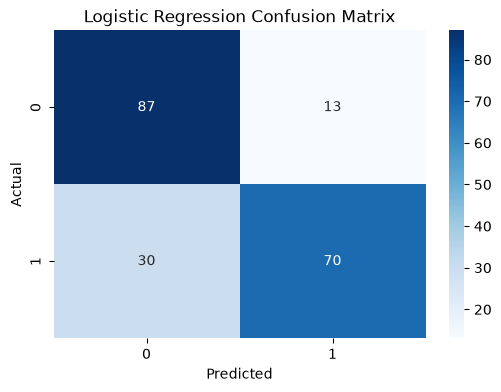

In [14]:
cm = confusion_matrix(
    y_test,
    lr_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [15]:
def predict_sentiment(text):

    text = clean_text(text)

    vector = vectorizer.transform(
        [text]
    )

    prediction = lr.predict(vector)

    if prediction[0] == 1:
        return "Positive"

    return "Negative"

In [16]:
predict_sentiment(
    "This product is excellent and very high quality"
)

'Positive'

In [17]:
predict_sentiment(
    "Terrible quality and waste of money"
)

'Negative'

Conclusion
This project developed a sentiment classification model using Natural Language Processing techniques.

Customer reviews were cleaned and transformed into TF-IDF numerical representations. Multinomial Naive Bayes and Logistic Regression models were trained and evaluated using classification metrics.

The models successfully classified positive and negative reviews with strong predictive performance. An interactive sentiment prediction function was also implemented to classify custom user input.

Overall, the project demonstrates the application of NLP and machine learning techniques to customer review sentiment analysis.